In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import yaml
from shapely import STRtree
from shapely.geometry import Point

from thesis.data.sampling import (
    filter_footprints,
    image_extent,
    image_is_rural,
    load_urban_areas,
    pin_hits_other_footprint,
    target_fits_image,
)

sampling_cfg = yaml.safe_load(Path("/Users/phillip/repositories/bachelor-thesis/configs/sampling.yaml").read_text())
imagery_cfg = yaml.safe_load(Path("/Users/phillip/repositories/bachelor-thesis/configs/imagery.yaml").read_text())

METRIC_CRS = "EPSG:5070"
IMAGE_WIDTH_M = imagery_cfg["image_px"] * imagery_cfg["gsd_m"]

In [2]:
# IMAGE_WIDTH_M

urban_path = sampling_cfg["census_urban"]["path"]

urban = load_urban_areas(urban_path, target_crs=METRIC_CRS)

print("urban areas:", len(urban))
print("CRS:", urban.crs)
print("all valid:", urban.geometry.is_valid.all())

footprints_path = Path("/Users/phillip/repositories/bachelor-thesis/data/playground_backup/footprints.parquet")

footprints = gpd.read_parquet(footprints_path)
footprints["source_index"] = footprints.index

print(footprints.crs)
footprints.head()

urban areas: 2644
CRS: EPSG:5070
all valid: True
OGC:CRS84


,building_id,box_name,geometry,footprint_m2_area,anchor_lon,anchor_lat,is_valid,geometry_type,source_index
0,d00bbbec-8d07-4d98-91e3-1e05366953e0,test_bbox,"POLYGON ((-103.45451 44.70908, -103.45452 44.7...",121.260847,-103.454555,44.709135,True,POLYGON,0
1,76627a46-e41c-43c2-9f52-f841819abde1,test_bbox,"POLYGON ((-103.45487 44.70923, -103.45487 44.7...",72.986573,-103.454789,44.709199,True,POLYGON,1
2,3014e6ed-383d-42e0-91e2-d91a3f0629d8,test_bbox,"POLYGON ((-103.47187 44.70945, -103.47187 44.7...",87.803355,-103.471924,44.709493,True,POLYGON,2
3,bafb08ec-094a-47ff-87cb-ea3f41e3be2b,test_bbox,"POLYGON ((-103.42154 44.71054, -103.42154 44.7...",150.749272,-103.421535,44.710493,True,POLYGON,3
4,877816f8-1366-42a9-9843-99b7102d405e,test_bbox,"POLYGON ((-103.42084 44.71061, -103.42099 44.7...",157.066885,-103.420917,44.710568,True,POLYGON,4


In [3]:
elig, stg = filter_footprints(
    footprints,
    min_area_m2=sampling_cfg["min_footprint_area_m2"],
    max_aspect_ratio=sampling_cfg["max_aspect_ratio"],
)

print(elig.head())
print()
print(len(stg))
stg[0]

                            building_id   box_name  \
0  d00bbbec-8d07-4d98-91e3-1e05366953e0  test_bbox   
3  bafb08ec-094a-47ff-87cb-ea3f41e3be2b  test_bbox   
4  877816f8-1366-42a9-9843-99b7102d405e  test_bbox   
7  42da9158-f663-4be5-8693-f017231f7632  test_bbox   
8  36a7fc6d-a442-4c0b-9ca1-a12e9bf10639  test_bbox   

                                            geometry  footprint_m2_area  \
0  POLYGON ((-103.45451 44.70908, -103.45452 44.7...         121.260877   
3  POLYGON ((-103.42154 44.71054, -103.42154 44.7...         150.749309   
4  POLYGON ((-103.42084 44.71061, -103.42099 44.7...         157.066923   
7  POLYGON ((-103.42433 44.71062, -103.42433 44.7...         230.372027   
8  POLYGON ((-103.42155 44.71074, -103.42173 44.7...         154.166370   

   anchor_lon  anchor_lat  is_valid geometry_type  source_index  aspect_ratio  
0 -103.454555   44.709135      True       POLYGON             0      1.717654  
3 -103.421535   44.710493      True       POLYGON             3 

RetentionStage(name='input', count=912, fraction_of_input=1.0, fraction_of_previous=1.0)

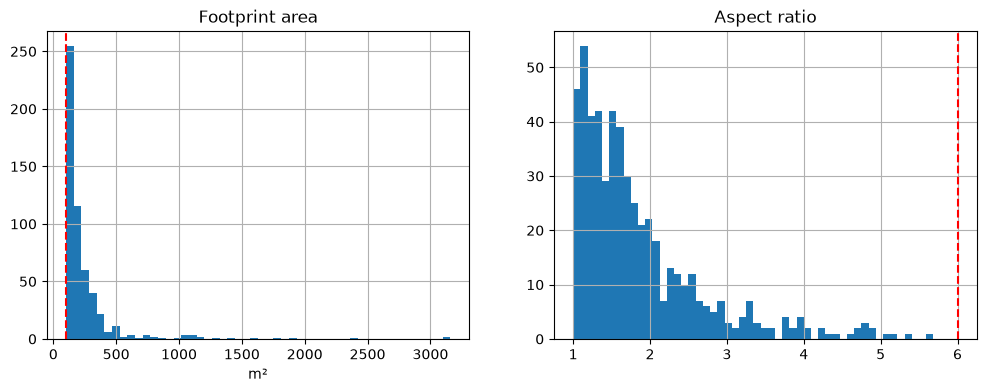

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
elig["footprint_m2_area"].hist(bins=50, ax=axes[0])
axes[0].axvline(
    sampling_cfg["min_footprint_area_m2"],
    color="red",
    linestyle="--",
)
axes[0].set_title("Footprint area")
axes[0].set_xlabel("m²")
elig["aspect_ratio"].hist(bins=50, ax=axes[1])
axes[1].axvline(
    sampling_cfg["max_aspect_ratio"],
    color="red",
    linestyle="--",
)
axes[1].set_title("Aspect ratio")
plt.show()

In [5]:
eligible = elig.copy()

eligible_m = eligible.to_crs(METRIC_CRS).copy()

anchor_wgs84 = gpd.GeoSeries(
    gpd.points_from_xy(
        eligible["anchor_lon"],
        eligible["anchor_lat"],
    ),
    index=eligible.index,
    crs=footprints.crs,
)

anchors_m = anchor_wgs84.to_crs(METRIC_CRS)
eligible_m["anchor"] = list(anchors_m)

mask_for_valids = (
    footprints.geometry.notna() & (footprints.geometry.geom_type == "Polygon") & footprints.geometry.is_valid
)

all_valids_m = footprints.loc[mask_for_valids].to_crs(METRIC_CRS).reset_index(drop=True)

footprint_tree = STRtree(all_valids_m.geometry.to_numpy())

tree_position_by_source = {
    source_index: tree_position for tree_position, source_index in enumerate(all_valids_m["source_index"])
}

In [6]:
from thesis.geometry.signed_distance import signed_distance_m


def evaluate_candidate(source_index, dx_m, dy_m):
    candidate = eligible_m.loc[eligible_m["source_index"] == source_index].iloc[0]
    target = candidate.geometry
    anchor = candidate.anchor

    moved_pin = Point(anchor.x + dx_m, anchor.y + dy_m)
    crop = image_extent(moved_pin, IMAGE_WIDTH_M)
    pin_on_target = target.covers(moved_pin)
    signed_edge_distance = signed_distance_m(moved_pin, target)
    rural = image_is_rural(crop, STRtree(urban.geometry.to_numpy()), buffer_m=sampling_cfg["census_urban"]["buffer_m"])
    target_fits = target_fits_image(target, moved_pin, crop)
    target_tree_position = tree_position_by_source[source_index]
    collision_free = not pin_hits_other_footprint(moved_pin, target_tree_position, footprint_tree)
    accepted = rural and target_fits and collision_free

    return {
        "source_index": source_index,
        "building_id": candidate.building_id,
        "dx_m": dx_m,
        "dy_m": dy_m,
        "label": "postive" if pin_on_target else "negative",
        "signed_distance_m": signed_edge_distance,
        "rural": rural,
        "target_fits": target_fits,
        "collision_free": collision_free,
        "accepted": accepted,
        "target": target,
        "anchor": anchor,
        "pin": moved_pin,
        "crop": crop,
    }


source_index = eligible_m.iloc[0]["source_index"]

trials = [
    evaluate_candidate(source_index, dx_m=0, dy_m=0),
    evaluate_candidate(source_index, dx_m=25, dy_m=0),
    evaluate_candidate(source_index, dx_m=50, dy_m=0),
    evaluate_candidate(source_index, dx_m=100, dy_m=0),
]

pd.DataFrame(trials).drop(columns=["target", "anchor", "pin", "crop"])

,source_index,building_id,dx_m,dy_m,label,signed_distance_m,rural,target_fits,collision_free,accepted
0,0,d00bbbec-8d07-4d98-91e3-1e05366953e0,0,0,postive,-3.287856,True,True,True,True
1,0,d00bbbec-8d07-4d98-91e3-1e05366953e0,25,0,negative,21.667208,True,True,True,True
2,0,d00bbbec-8d07-4d98-91e3-1e05366953e0,50,0,negative,46.622304,True,True,True,True
3,0,d00bbbec-8d07-4d98-91e3-1e05366953e0,100,0,negative,96.532494,True,True,True,True


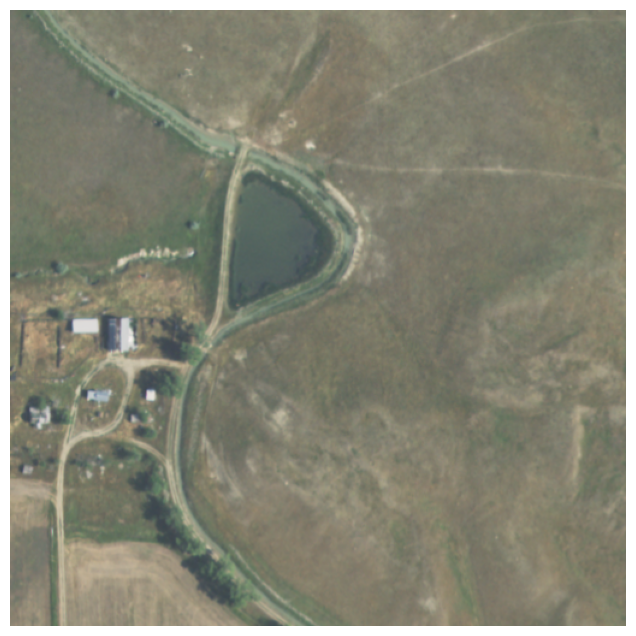

In [7]:
from thesis.data.naip import fetch_tile

result = trials[-1]

pin_wgs84 = (
    gpd.GeoSeries(
        [result["pin"]],
        crs=METRIC_CRS,
    )
    .to_crs("EPSG:4326")
    .iloc[0]
)

tile = fetch_tile(
    lat=pin_wgs84.y,
    lon=pin_wgs84.x,
    gsd=imagery_cfg["gsd_m"],
    size=imagery_cfg["image_px"],
    config=imagery_cfg,
)

assert tile.array.shape == (3, 512, 512)
assert tile.metadata["extent_m"] == IMAGE_WIDTH_M
assert abs(tile.metadata["px"] - 256) <= 1
assert abs(tile.metadata["py"] - 256) <= 1

plt.figure(figsize=(8, 8))
plt.imshow(tile.array.transpose(1, 2, 0))
plt.axis("off")
plt.show()

In [8]:
import os
import subprocess

# this is kinda annoying...
# cairo specific issue
prefix = subprocess.check_output(["brew", "--prefix", "cairo"], text=True).strip()
os.environ["DYLD_LIBRARY_PATH"] = f"{prefix}/lib"

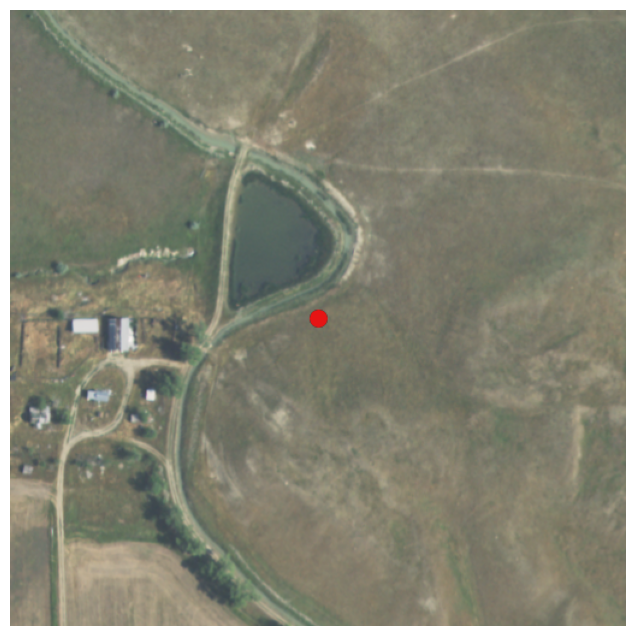

In [ ]:
from thesis.render.marker import draw_marker

render_cfg = yaml.safe_load(Path("/Users/phillip/repositories/bachelor-thesis/configs/render.yaml").read_text())

marked = draw_marker(
    tile.array,
    px=tile.metadata["px"],
    py=tile.metadata["py"],
    shape="crosshair",
    color=tuple(render_cfg["colors"]["red"]),
    size_px=render_cfg["size_px"],
    opacity=render_cfg["opacity"],
)

plt.figure(figsize=(8, 8))
plt.imshow(marked.transpose(1, 2, 0))
plt.axis("off")
plt.show()